# Disaster Tweet Classification: TF-IDF Baselines vs. DistilBERT

This project evaluates classical TF-IDF-based machine learning models and a
fine-tuned DistilBERT model for binary disaster tweet classification.
Performance is evaluated using F1 score on stratified train, validation, and
test splits.

In [97]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import tf_keras

import re
import html

from sklearn import set_config
set_config(display="text")
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


from transformers import AutoTokenizer, TFDistilBertForSequenceClassification

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# If the notebook is run from notebooks/, move to the project root
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

# EDA

In [100]:
class EDA():
    def __init__(self, train_path):
        self.train_data = pd.read_csv(train_path)  

    def view_data(self):
        # view basic information
        print("==============================Basic Data information=================================")
        print(self.train_data.info())
        print(self.train_data.head())

    def count_class_distri(self):
        # count the distribution of class "target" of data 
        print("==============================Class Distribution Count=================================")
        class_counts = self.train_data['target'].value_counts()
        print(class_counts)

        # visualize the distribution of class "target" of data 
        plt.figure (figsize=(6, 4))
        sns.countplot (data=self.train_data, x='target')
        plt.title ('Class Distribution')
        plt.xlabel ('Class')
        plt.ylabel ('Count')
        plt.show ()

    def tweet_length_distri(self):
        # demonstrate descriptive statistical indicators of tweet lengths
        print("==============================Tweet Length Statistics=================================")
        self.train_data['tweet_length'] = self.train_data['text'].apply(lambda x: len(x.split()))
        tweet_length_stats = self.train_data['tweet_length'].describe()
        print(tweet_length_stats)
    
        # Plot boxplot for the distribution of tweet lengths
        plt.figure(figsize=(6, 4))
        sns.boxplot(data=self.train_data, y='tweet_length')
        plt.title('Tweet Length Distribution')
        plt.ylabel('Tweet Length')
        plt.show()

    
    def run_full_EDA(self):
        self.view_data()
        self.count_class_distri()
        self.tweet_length_distri()
        print("==============================EDA Completed=================================")



        
        

==============================Basic Data information=================================
<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7613 non-null   int64
 1   keyword   7552 non-null   str  
 2   location  5080 non-null   str  
 3   text      7613 non-null   str  
 4   target    7613 non-null   int64
dtypes: int64(2), str(3)
memory usage: 297.5 KB
None
   id keyword location                                               text  \
0   1     NaN      NaN  Our Deeds are the Reason of this #earthquake M...   
1   4     NaN      NaN             Forest fire near La Ronge Sask. Canada   
2   5     NaN      NaN  All residents asked to 'shelter in place' are ...   
3   6     NaN      NaN  13,000 people receive #wildfires evacuation or...   
4   7     NaN      NaN  Just got sent this photo from Ruby #Alaska as ...   

   target  
0       1  
1       1  
2       

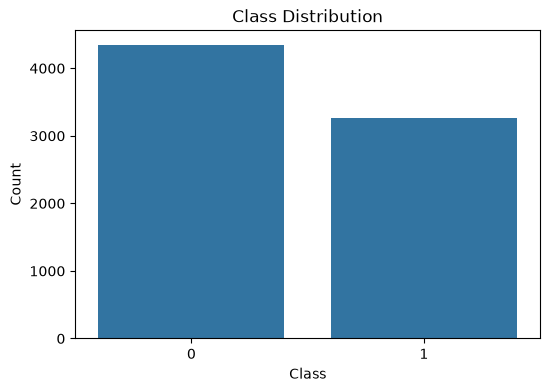

==============================Tweet Length Statistics=================================
count    7613.000000
mean       14.903586
std         5.732604
min         1.000000
25%        11.000000
50%        15.000000
75%        19.000000
max        31.000000
Name: tweet_length, dtype: float64


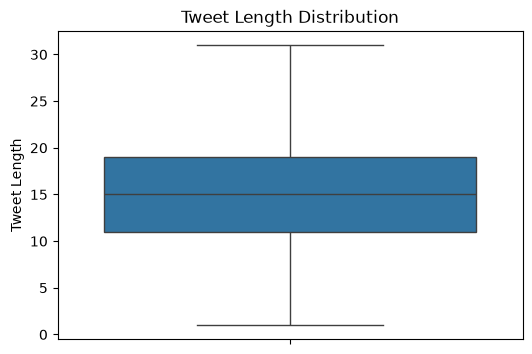

==============================EDA Completed=================================


In [101]:
train_data = EDA(TRAIN_PATH)

train_data.run_full_EDA()

# Data cleaning

In [102]:
class tweetcleaner():
    def __init__(self):
        pass 
    
    # basic data cleaning：fill NA type data, delete duplicated text
    def basic_clean(self, df):
        df = df.copy()   # avoid changing the original data
        df = df.fillna("")
        df = df.drop_duplicates(subset=["text"])
        return df
    
    # Regular Expression-based Text Denoising 
    def single_tweet_clean(self, text, lower=False):
        # decode HTML entities
        text = html.unescape(text)
        # delete URL
        text = re.sub(r'http\S+|www\S+|https\S+', '', text)
        # delete @user
        text = re.sub(r'@\w+', '', text)
        # delete extra whitespace
        text = re.sub(r'\s+', ' ', text).strip()
        # text lowercasing(especially for Machine Learning)
        if lower == True:
            text = text.lower()
        return text
    
    def text_denoise(self, df, lower = False):
        df = df.copy()  # avoid changing the original data
        df["clean_text"] = df["text"].apply(lambda x: self.single_tweet_clean(x, lower=lower))
        return df
    
    
    
    def run_full_clean(self, df, lower = False):
        df = self.basic_clean(df)
        df = self.text_denoise(df, lower)
        return df




In [103]:
df_train = train_data.train_data
cleaner = tweetcleaner()

clean_df_train = cleaner.run_full_clean(df_train,lower = True)
print(type(clean_df_train))

<class 'pandas.DataFrame'>


# Dataset Split

In [104]:
# Combine text columns
clean_df_train["combined_text"] = (clean_df_train["keyword"] + " " + 
                                   clean_df_train["location"] + " " +
                                   clean_df_train["clean_text"])

In [105]:
X = clean_df_train["combined_text"]
y = clean_df_train["target"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, random_state=42,
    stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=1/9, 
                                                  stratify=y_temp, random_state=42)


In [106]:
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Train: 6001
Validation: 751
Test: 751

Train distribution:
target
0    0.573738
1    0.426262
Name: proportion, dtype: float64

Validation distribution:
target
0    0.573901
1    0.426099
Name: proportion, dtype: float64

Test distribution:
target
0    0.573901
1    0.426099
Name: proportion, dtype: float64


# Machine Learning Algorithms Implementation：Based on TF-IDF

## 1. SVM

In [107]:
model_SVM = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1,2),
        min_df=2,
        sublinear_tf=True,
        max_features=20000
    )),
    ("svm", LinearSVC(random_state=42, max_iter=5000))
])


model_SVM.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('svm', LinearSVC(max_iter=5000, random_state=42))])

In [108]:
train_pred_SVM= model_SVM.predict(X_train)
validation_pred_SVM = model_SVM.predict(X_val)
test_pred_SVM = model_SVM.predict(X_test)

print(f"f1_score of Train: {f1_score(y_train, train_pred_SVM):.4f}")
print(f"f1_score of Validation: {f1_score(y_val, validation_pred_SVM):.4f}")
print(f"f1_score of Test: {f1_score(y_test, test_pred_SVM):.4f}")


f1_score of Train: 0.9566
f1_score of Validation: 0.7252
f1_score of Test: 0.7401


## 2. Logistic Regression

In [109]:
model_LogisticRegrssion = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1,2),
        min_df=2,
        sublinear_tf=True,
        max_features=20000
    )),
    ("LogisticRegrssion", LogisticRegression(random_state=42, max_iter=5000))
])


model_LogisticRegrssion.fit(X_train, y_train);

In [110]:
train_pred_LogisticRegrssion = model_LogisticRegrssion.predict(X_train)
validation_pred_LogisticRegrssion = model_LogisticRegrssion.predict(X_val)
test_pred_LogisticRegrssion = model_LogisticRegrssion.predict(X_test)

print(f"f1_score of Train: {f1_score(y_train, train_pred_LogisticRegrssion):.4f}")
print(f"f1_score of Validation: {f1_score(y_val, validation_pred_LogisticRegrssion):.4f}")
print(f"f1_score of Test: {f1_score(y_test, test_pred_LogisticRegrssion):.4f}")


f1_score of Train: 0.8462
f1_score of Validation: 0.7381
f1_score of Test: 0.7630


## 3. KNN

In [111]:
model_KNN = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1,2),
        min_df=2,
        sublinear_tf=True,
        max_features=20000
    )),
    ("KNN", KNeighborsClassifier(n_neighbors=5))
])


model_KNN.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('KNN', KNeighborsClassifier())])

In [112]:
train_pred_KNN = model_KNN.predict(X_train)
validation_pred_KNN = model_KNN.predict(X_val)
test_pred_KNN = model_KNN.predict(X_test)

print(f"f1_score of Train: {f1_score(y_train, train_pred_KNN):.4f}")
print(f"f1_score of Validation: {f1_score(y_val, validation_pred_KNN):.4f}")
print(f"f1_score of Test: {f1_score(y_test, test_pred_KNN):.4f}")

f1_score of Train: 0.7606
f1_score of Validation: 0.6606
f1_score of Test: 0.6423


## 4. Random Forest

In [113]:
model_RandomForest = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1,2),
        min_df=2,
        sublinear_tf=True,
        max_features=20000
    )),
    ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=42))
])


model_RandomForest.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('RandomForest', RandomForestClassifier(random_state=42))])

In [114]:
train_pred_RandomForest = model_RandomForest.predict(X_train)
validation_pred_RandomForest = model_RandomForest.predict(X_val)
test_pred_RandomForest = model_RandomForest.predict(X_test)

print(f"f1_score of Train: {f1_score(y_train, train_pred_RandomForest):.4f}")
print(f"f1_score of Validation: {f1_score(y_val, validation_pred_RandomForest):.4f}")
print(f"f1_score of Test: {f1_score(y_test, test_pred_RandomForest):.4f}")



f1_score of Train: 0.9937
f1_score of Validation: 0.7011
f1_score of Test: 0.7160


In [115]:
results_df = pd.DataFrame({
    "Model": [
        "SVM",
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],
    "Validation F1": [
        f1_score(y_val, validation_pred_SVM),
        f1_score(y_val, validation_pred_LogisticRegrssion),
        f1_score(y_val, validation_pred_KNN),
        f1_score(y_val, validation_pred_RandomForest)
    ],
    "Test F1": [
        f1_score(y_test, test_pred_SVM),
        f1_score(y_test, test_pred_LogisticRegrssion),
        f1_score(y_test, test_pred_KNN),
        f1_score(y_test, test_pred_RandomForest)
    ]
})

results_df.sort_values("Validation F1", ascending=False)

,Model,Validation F1,Test F1
1,Logistic Regression,0.738095,0.763025
0,SVM,0.725203,0.740132
3,Random Forest,0.701068,0.716007
2,KNN,0.660584,0.642336


# Deep Learning Base on DistilBERT

## Tokenizer Loading

In [ ]:
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)


# Standardize all texts to identical-length numeric sequences for batch training
def encode_text(text_list, max_len):
    enc = tokenizer(
        text_list.tolist(),
        padding="max_length",
        truncation=True,
        max_length=max_len,
        return_tensors="tf"
    )
    return enc["input_ids"], enc["attention_mask"]





In [117]:
MAX_LEN = 32
train_ids, train_mask = encode_text(X_train, MAX_LEN)
val_ids, val_mask = encode_text(X_val, MAX_LEN)
test_ids, test_mask = encode_text(X_test, MAX_LEN)



## Model initialization

In [118]:
model_bert_classifier = TFDistilBertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    use_safetensors=False
)




Some layers from the model checkpoint at distilbert-base-uncased were not used when initializing TFDistilBertForSequenceClassification: ['activation_13', 'vocab_layer_norm', 'vocab_projector', 'vocab_transform']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFDistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['pre_classifier', 'dropout_193', 'classifier']
You should probably TRAIN this model on a down-stream task to be able to use 

In [ ]:
model_bert_classifier.compile(
    optimizer=tf_keras.optimizers.Adam(
        learning_rate=2e-5
    ),
    loss=tf_keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=[
        tf_keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

## Training & Testing

In [120]:
EPOCHS = 3
BATCH_SIZE = 32

history = model_bert_classifier.fit(
    {
        "input_ids": train_ids,
        "attention_mask": train_mask
    },
    y_train.to_numpy(),
    validation_data=(
        {
            "input_ids": val_ids,
            "attention_mask": val_mask
        },
        y_val.to_numpy()
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/3
188/188 [==============================] - 227s 1s/step - loss: 0.4587 - accuracy: 0.7937 - val_loss: 0.4135 - val_accuracy: 0.8216
Epoch 2/3
188/188 [==============================] - 206s 1s/step - loss: 0.3319 - accuracy: 0.8674 - val_loss: 0.4560 - val_accuracy: 0.8083
Epoch 3/3
188/188 [==============================] - 179s 952ms/step - loss: 0.2612 - accuracy: 0.9023 - val_loss: 0.5394 - val_accuracy: 0.7803


In [121]:
test_outputs = model_bert_classifier.predict({
    "input_ids": test_ids,
    "attention_mask": test_mask
})

test_logits = test_outputs.logits
test_pred_BERT = np.argmax(test_logits, axis=1)

bert_test_f1 = f1_score(y_test, test_pred_BERT)

print("BERT Test F1:", bert_test_f1)

24/24 [==============================] - 8s 307ms/step
BERT Test F1: 0.7669172932330827


In [122]:
val_outputs = model_bert_classifier.predict({
    "input_ids": val_ids,
    "attention_mask": val_mask
})

val_logits = val_outputs.logits
val_pred_BERT = np.argmax(val_logits, axis=1)

bert_val_f1 = f1_score(y_val, val_pred_BERT)

print("BERT Validation F1:", bert_val_f1)

24/24 [==============================] - 7s 304ms/step
BERT Validation F1: 0.7577092511013216


##  Results Evaluation

In [123]:
classical_results_df = results_df[
    results_df["Model"] != "DistilBERT"
].copy()

bert_result = pd.DataFrame({
    "Model": ["DistilBERT"],
    "Validation F1": [bert_val_f1],
    "Test F1": [bert_test_f1]
})

final_results_df = pd.concat(
    [classical_results_df, bert_result],
    ignore_index=True
)

final_results_df = final_results_df.sort_values(
    by="Validation F1",
    ascending=False
).reset_index(drop=True)

final_results_df

,Model,Validation F1,Test F1
0,DistilBERT,0.757709,0.766917
1,Logistic Regression,0.738095,0.763025
2,SVM,0.725203,0.740132
3,Random Forest,0.701068,0.716007
4,KNN,0.660584,0.642336


### Model Comparison

DistilBERT achieved the highest validation F1 score (0.758) and test F1 score (0.767), slightly outperforming TF-IDF with Logistic Regression, which achieved a test F1 score of 0.763. The small performance gap suggests that classical TF-IDF-based models remain highly competitive on this relatively small tweet classification dataset, while transformer fine-tuning provides a modest additional improvement.